# L1B exploration: Sockeye Fire, 2015-06-15 11:30 UTC (night)

VNP02IMG + VNP03IMG v002. Goals: check structure, BT conversion, quality flags,
and compare a first VIFDAHL run with the 2015 detections (GMT 1135).

Not production code: the reader will move to `vifdahl.readers.l1b`.

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

from vifdahl.algorithm import classify
from vifdahl.events import load_events
from vifdahl.swath import duplicate_pixels, scene_is_day

RAW = Path("../data/raw/l1b")
F02 = next(RAW.glob("VNP02IMG.A2015166.1130.*.nc"))
F03 = next(RAW.glob("VNP03IMG.A2015166.1130.*.nc"))
event = load_events()["sockeye"]

## Load (raw values, no automatic scaling)

In [2]:
obs = xr.open_dataset(F02, group="observation_data", engine="h5netcdf", mask_and_scale=False)
geo = xr.open_dataset(F03, group="geolocation_data", engine="h5netcdf")
meta = xr.open_dataset(F03, engine="h5netcdf")
{k: meta.attrs[k] for k in ("OrbitNumber", "StartTime", "startDirection", "DayNightFlag", "platform")}

{'OrbitNumber': np.int32(18814),
 'StartTime': '2015-06-15 11:30:00.000',
 'startDirection': 'Descending',
 'DayNightFlag': 'Day',
 'platform': 'Suomi-NPP'}

## Crop to the AOI

Rows are extended to whole scans (32 lines) plus one scan on each side, for scan-overlap detection.

In [3]:
SCAN = 32
w, s, e, n = event.bbox()
lat, lon = geo["latitude"].values, geo["longitude"].values
inside = (lon >= w) & (lon <= e) & (lat >= s) & (lat <= n)
rows, cols = np.nonzero(inside)
r0, r1 = (rows.min() // SCAN - 1) * SCAN, (rows.max() // SCAN + 2) * SCAN
crop = dict(number_of_lines=slice(max(r0, 0), r1),
            number_of_pixels=slice(cols.min(), cols.max() + 1))
o, g = obs.isel(crop), geo.isel(crop)
o.sizes

Frozen({'number_of_lines': 192, 'number_of_pixels': 41, 'number_of_LUT_values': 65536})

## Brightness temperature via lookup table

Raw values ≥ 65532 are fill/flags (Missing_EV, Bowtie_Deleted, Cal_Fail).

In [4]:
FLAG_MIN = 65532

def to_bt(dn: xr.DataArray, lut: xr.DataArray) -> np.ndarray:
    dn = dn.values.astype(np.int64)
    bt = lut.values[np.clip(dn, 0, len(lut) - 1)].astype(float)
    bt[(dn >= FLAG_MIN) | (bt < 0)] = np.nan
    return bt

i4 = to_bt(o["I04"], obs["I04_brightness_temperature_lut"])
i5 = to_bt(o["I05"], obs["I05_brightness_temperature_lut"])
print("I4 range:", np.nanmin(i4), np.nanmax(i4), " LUT max:", float(obs["I04_brightness_temperature_lut"].max()))
print("I5 range:", np.nanmin(i5), np.nanmax(i5))
print("fill/flag pixels I4:", int(np.isnan(i4).sum()))

I4 range: 275.3360900878906 332.6686706542969  LUT max: 361.77587890625
I5 range: 276.210693359375 288.869873046875
fill/flag pixels I4: 984


## Quality flags present in the crop

In [5]:
BITS = {1: "Substitute_Cal", 2: "Out_of_Range", 4: "Saturation", 8: "Temp_not_Nominal",
        256: "Bowtie_Deleted", 512: "Missing_EV", 1024: "Cal_Fail", 2048: "Dead_Detector", 4096: "Noisy_Detector"}
for band in ("I04", "I05"):
    qf = o[f"{band}_quality_flags"].values
    print(band, {name: int(((qf & bit) > 0).sum()) for bit, name in BITS.items() if ((qf & bit) > 0).any()})

I04 {'Bowtie_Deleted': 984}
I05 {'Bowtie_Deleted': 984}


## Images

solar zenith in crop: 92.42 – 93.119995 → scene is day: False


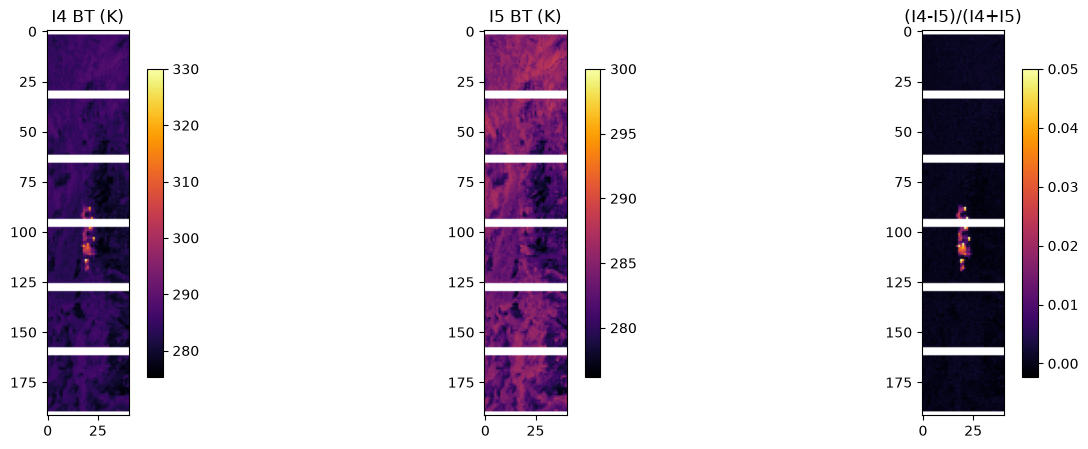

In [6]:
sza = g["solar_zenith"].values
ndiff = (i4 - i5) / (i4 + i5)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, arr, title, vmax in zip(axes, [i4, i5, ndiff], ["I4 BT (K)", "I5 BT (K)", "(I4-I5)/(I4+I5)"],
                                [330, 300, 0.05]):
    im = ax.imshow(arr, vmax=vmax, cmap="inferno")
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.8)
print("solar zenith in crop:", np.nanmin(sza), "–", np.nanmax(sza), "→ scene is day:", scene_is_day(sza))

## First VIFDAHL run (provisional anomaly mask)

Assumption to verify: L1B anomaly ≈ I4 `Saturation` or `Out_of_Range` flag.

In [7]:
qf4 = o["I04_quality_flags"].values
anomalous = (qf4 & (2 | 4)) > 0
day = scene_is_day(sza)
masks = classify(i4, i5, anomalous, day)
print("before duplicate removal:", {k: int(v.sum()) for k, v in masks._asdict().items()})
ascending = meta.attrs["startDirection"] == "Ascending"
dup = duplicate_pixels(g["latitude"].values, ascending)
masks = type(masks)(*(m & ~dup for m in masks))
print("after:", {k: int(v.sum()) for k, v in masks._asdict().items()})

before duplicate removal: {'anomalous': 0, 'hot': 5, 'warm': 62}
after: {'anomalous': 0, 'hot': 4, 'warm': 49}


## Compare with 2015 VIFDAHL detections (same overpass)

{'L': 49, 'H': 4}
old TB4: 290.3402099609375 – 332.6531677246094  old TB5: 281.228515625 – 288.5187683105469


/var/folders/jh/dmrl1jcn7ql6ftcyq7l6p8v80000gn/T/ipykernel_32679/2619034379.py:8: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  ax.pcolormesh(clon, clat, i4, vmax=330, cmap="gray", shading="auto")


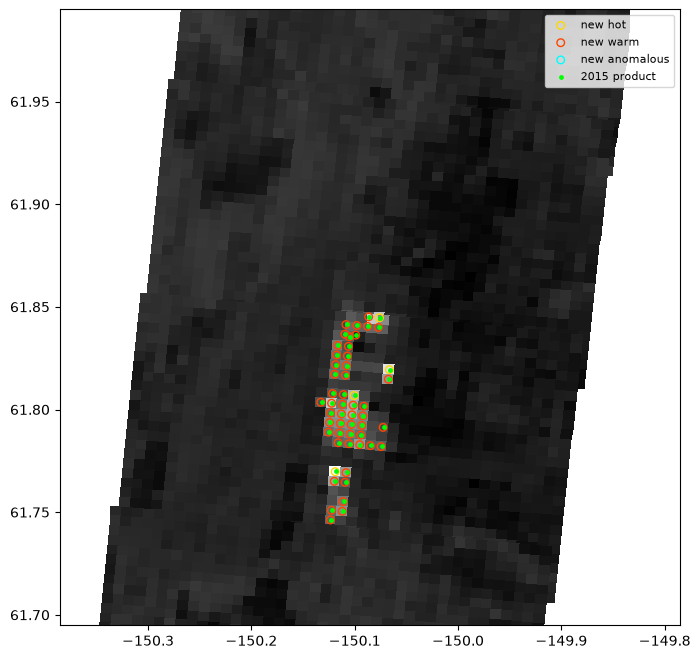

In [8]:
old = gpd.read_file("../data/reference/2015_vifdahl_detections/sockeyeviirsspoly.shp")
old = old[(old["DATE"] == "2015-06-15") & (old["GMT"] == "1135")]
print(old["Type"].value_counts().to_dict())
print("old TB4:", old["TB4"].min(), "–", old["TB4"].max(), " old TB5:", old["TB5"].min(), "–", old["TB5"].max())

clat, clon = g["latitude"].values, g["longitude"].values
fig, ax = plt.subplots(figsize=(8, 8))
ax.pcolormesh(clon, clat, i4, vmax=330, cmap="gray", shading="auto")
for name, color in (("hot", "gold"), ("warm", "orangered"), ("anomalous", "cyan")):
    m = getattr(masks, name)
    ax.scatter(clon[m], clat[m], s=30, facecolors="none", edgecolors=color, label=f"new {name}")
ax.scatter(old["LON"], old["LAT"], s=6, c="lime", label="2015 product")
ax.set_xlim(event.center_lon - 0.3, event.center_lon + 0.3)
ax.set_ylim(event.center_lat - 0.15, event.center_lat + 0.15)
ax.legend(fontsize=8);

In [9]:
# One-to-one match: nearest new detection for each 2015 detection
import pandas as pd
from scipy.spatial import cKDTree
fire = masks.hot | masks.warm
new = pd.DataFrame({"LON": clon[fire], "LAT": clat[fire], "TB4": i4[fire],
                    "Type": np.where(masks.hot[fire], "H", "L")})
dist, idx = cKDTree(new[["LON", "LAT"]].values).query(old[["LON", "LAT"]].values)
match = new.iloc[idx].reset_index(drop=True)
print(f"new detections: {len(new)}, 2015: {len(old)}, distinct matches: {len(set(idx))}")
print(f"position offset: median {np.median(dist):.5f}°, max {dist.max():.5f}°")
print(f"max |dTB4|: {np.abs(old['TB4'].values - match['TB4'].values).max():.3f} K")
pd.crosstab(old["Type"].rename("2015").values, match["Type"].rename("new").values)

new detections: 53, 2015: 53, distinct matches: 53
position offset: median 0.00072°, max 0.00081°
max |dTB4|: 0.016 K


col_0,H,L
row_0,,
H,4,0
L,0,49
